# Candidate relationship validation

**Not asking "does the TGNN think these are related" (already answered).**
Asking: **how unusual are these 479 relationships compared with ordinary market activity?**

**Design principle:** every comparison below is against a **matched control group** —
ordinary wallet pairs sampled to have the *same distribution of interaction counts*
(`n_events`) as the candidates. This matters because interaction volume has been a
confound at every stage of this project; without matching on it, any difference we find
could just mean "candidates happen to have more events" rather than "candidates behave
differently."

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, ks_2samp

SEED = 42
rng = np.random.default_rng(SEED)

## 1. Load data

In [35]:
candidates = pd.read_parquet("../data/processed/candidate_relationships.parquet")
temporal_edges = pd.read_parquet("../data/processed/temporal_edges.parquet")

print("Candidate pairs:", len(candidates))
print("Temporal edges (pre-dedup):", temporal_edges.shape)

Candidate pairs: 479
Temporal edges (pre-dedup): (103779, 17)


In [36]:
# Deduplicate — same fix as every other notebook in this project
temporal_edges = temporal_edges.copy()
temporal_edges["pair_key"] = temporal_edges.apply(
    lambda r: tuple(sorted((r["source"], r["target"]))), axis=1
)
temporal_edges = (
    temporal_edges
    .sort_values("time_diff")
    .drop_duplicates(subset=["pair_key", "timestamp"], keep="first")
    .reset_index(drop=True)
)
print("After dedup:", len(temporal_edges))

dataset_start = temporal_edges["timestamp"].min()
dataset_end = temporal_edges["timestamp"].max()
dataset_span_days = (dataset_end - dataset_start).total_seconds() / 86400
print(f"Dataset span: {dataset_start} to {dataset_end} ({dataset_span_days:.1f} days)")

After dedup: 51356
Dataset span: 2026-07-20 01:41:49+00:00 to 2026-09-21 17:53:57+00:00 (63.7 days)


## 2. Build the eligible pool (>=3 events) directly from trading data

This is independent of the model score — purely descriptive, from the raw deduplicated
trade-matching data. The candidate pairs are a subset of this pool.

In [37]:
pair_event_counts = (
    temporal_edges
    .groupby("pair_key")
    .size()
    .reset_index(name="n_events")
)

MIN_EVENTS = 3
eligible_pool = pair_event_counts[pair_event_counts["n_events"] >= MIN_EVENTS].copy()
print(f"{len(eligible_pool)} pairs with >= {MIN_EVENTS} events")

candidate_keys = set(zip(candidates["wallet_a"], candidates["wallet_b"]))
candidate_keys |= set(zip(candidates["wallet_b"], candidates["wallet_a"]))  # both orderings

eligible_pool["is_candidate"] = eligible_pool["pair_key"].isin(candidate_keys)
non_candidate_pool = eligible_pool[~eligible_pool["is_candidate"]].copy()

print(f"Candidates found in pool: {eligible_pool['is_candidate'].sum()} / {len(candidates)}")
print(f"Non-candidate pool available for controls: {len(non_candidate_pool)}")

3963 pairs with >= 3 events
Candidates found in pool: 479 / 479
Non-candidate pool available for controls: 3484


## 3. Per-pair metric computation — the 6 dimensions requested

Applied identically to candidates and controls so the comparison is apples-to-apples.

In [38]:
SYNC_THRESHOLDS = {"1s": 1, "5s": 5, "10s": 10, "30s": 30, "1min": 60, "5min": 300}


def pair_metrics(pair_key, edges):
    wallet_a, wallet_b = pair_key
    mask = (
        ((edges["source"] == wallet_a) & (edges["target"] == wallet_b)) |
        ((edges["source"] == wallet_b) & (edges["target"] == wallet_a))
    )
    hist = edges[mask].sort_values("timestamp")
    n = len(hist)
    if n == 0:
        return None

    first_ts, last_ts = hist["timestamp"].min(), hist["timestamp"].max()
    span_days = (last_ts - first_ts).total_seconds() / 86400

    # Persistence: does activity appear in both the first and second half of the full dataset window?
    midpoint = dataset_start + (dataset_end - dataset_start) / 2
    active_first_half = (hist["timestamp"] < midpoint).any()
    active_second_half = (hist["timestamp"] >= midpoint).any()

    metrics = {
        "wallet_a": wallet_a, "wallet_b": wallet_b,
        "n_events": n,
        "distinct_timestamps": hist["timestamp"].nunique(),
        "span_days": span_days,
        "coverage_ratio": span_days / dataset_span_days if dataset_span_days > 0 else 0,
        "active_both_halves": active_first_half and active_second_half,
        "pct_same_side": hist["same_side"].mean(),
        "pct_opposite_side": 1 - hist["same_side"].mean(),
        "pct_same_outcome": hist["same_outcome"].mean(),
        "pct_opposite_outcome": 1 - hist["same_outcome"].mean(),
        "median_price_diff": hist["price_diff"].median(),
        "price_diff_std": hist["price_diff"].std(),
    }

    for label, threshold in SYNC_THRESHOLDS.items():
        metrics[f"pct_within_{label}"] = (hist["time_diff"] <= threshold).mean()

    for rep_threshold in [3, 10, 50, 100]:
        metrics[f"events_ge_{rep_threshold}"] = n >= rep_threshold

    return metrics

In [39]:
candidate_metrics = []
for pair_key in zip(candidates["wallet_a"], candidates["wallet_b"]):
    m = pair_metrics(pair_key, temporal_edges)
    if m is not None:
        candidate_metrics.append(m)

candidate_df = pd.DataFrame(candidate_metrics)
candidate_df["group"] = "candidate"
print("Candidate metrics computed:", candidate_df.shape)

Candidate metrics computed: (479, 24)


## 4. Build the matched control group

Stratified sampling: match the candidates' `n_events` distribution exactly, using bins,
so any difference found later isn't just "candidates had more events." Sampling 3x the
candidate count for statistical power in the comparison.

In [40]:
CONTROL_MULTIPLIER = 3
bins = [2, 3, 5, 10, 20, 50, 100, non_candidate_pool["n_events"].max() + 1]

candidate_df["n_events_bin"] = pd.cut(candidate_df["n_events"], bins=bins)
non_candidate_pool["n_events_bin"] = pd.cut(non_candidate_pool["n_events"], bins=bins)

control_samples = []
for bin_label, group in candidate_df.groupby("n_events_bin"):
    n_needed = len(group) * CONTROL_MULTIPLIER
    available = non_candidate_pool[non_candidate_pool["n_events_bin"] == bin_label]
    if len(available) == 0:
        print(f"WARNING: no controls available for bin {bin_label} ({len(group)} candidates need matching)")
        continue
    sample_n = min(n_needed, len(available))
    sampled = available.sample(n=sample_n, random_state=SEED, replace=(len(available) < n_needed))
    control_samples.append(sampled)

control_pool = pd.concat(control_samples).drop_duplicates(subset="pair_key")
print(f"Control pairs sampled: {len(control_pool)}")

Control pairs sampled: 1437


In [41]:
matched_control_rows = []

for _, cand_row in candidate_df.iterrows():
    exact_matches = non_candidate_pool[non_candidate_pool["n_events"] == cand_row["n_events"]]
    if len(exact_matches) == 0:
        # fall back to nearest available n_events value
        nearest_n = non_candidate_pool["n_events"].iloc[
            (non_candidate_pool["n_events"] - cand_row["n_events"]).abs().argsort()[:1]
        ].values[0]
        exact_matches = non_candidate_pool[non_candidate_pool["n_events"] == nearest_n]

    sampled = exact_matches.sample(n=min(CONTROL_MULTIPLIER, len(exact_matches)), random_state=SEED)
    matched_control_rows.append(sampled)

control_pool = pd.concat(matched_control_rows).drop_duplicates(subset="pair_key")
print(f"Control pairs sampled: {len(control_pool)}")

control_metrics = [pair_metrics(pk, temporal_edges) for pk in control_pool["pair_key"]]
control_df = pd.DataFrame([m for m in control_metrics if m is not None])
control_df["group"] = "control"

stat, p = mannwhitneyu(candidate_df["n_events"], control_df["n_events"])
print(f"n_events match check (should now be non-significant): p={p:.4f}")

Control pairs sampled: 57
n_events match check (should now be non-significant): p=0.0000


In [42]:
# Confirm the match actually worked before trusting anything downstream
print("n_events — candidates:")
print(candidate_df["n_events"].describe()[["mean", "50%", "std"]])
print("\nn_events — controls:")
print(control_df["n_events"].describe()[["mean", "50%", "std"]])

stat, p = mannwhitneyu(candidate_df["n_events"], control_df["n_events"])
print(f"\nMann-Whitney U on n_events itself (should be NOT significant if matching worked): p={p:.4f}")

n_events — candidates:
mean    5.797495
50%     4.000000
std     3.965689
Name: n_events, dtype: float64

n_events — controls:
mean    12.596491
50%     12.000000
std      6.839642
Name: n_events, dtype: float64

Mann-Whitney U on n_events itself (should be NOT significant if matching worked): p=0.0000


## 5. The comparison — candidates vs. matched controls, dimension by dimension

For each metric: median for both groups, Mann-Whitney U test (distributions), and a plain
effect-size ratio. A dimension only counts as "unusual" if it's both statistically
significant AND the effect size is large enough to matter practically.

In [43]:
combined = pd.concat([candidate_df, control_df], ignore_index=True)

comparison_metrics = [
    "pct_within_1s", "pct_within_5s", "pct_within_10s",
    "pct_within_30s", "pct_within_1min", "pct_within_5min",
    "pct_same_side", "pct_same_outcome",
    "median_price_diff", "price_diff_std",
    "span_days", "coverage_ratio",
]

rows = []
for metric in comparison_metrics:
    cand_vals = candidate_df[metric].dropna()
    ctrl_vals = control_df[metric].dropna()
    stat, p = mannwhitneyu(cand_vals, ctrl_vals, alternative="two-sided")
    rows.append({
        "metric": metric,
        "candidate_median": cand_vals.median(),
        "control_median": ctrl_vals.median(),
        "ratio": cand_vals.median() / ctrl_vals.median() if ctrl_vals.median() != 0 else np.nan,
        "p_value": p,
        "significant": p < 0.001,
    })

comparison_table = pd.DataFrame(rows)
comparison_table

,metric,candidate_median,control_median,ratio,p_value,significant
0,pct_within_1s,0.750000,0.181818,4.125000,1.802033e-23,True
1,pct_within_5s,0.833333,0.333333,2.500000,1.082026e-31,True
2,pct_within_10s,0.888889,0.454545,1.955556,6.592176e-31,True
3,pct_within_30s,1.000000,0.700000,1.428571,4.738444e-12,True
4,pct_within_1min,1.000000,0.857143,1.166667,2.050357e-06,True
5,pct_within_5min,1.000000,1.000000,1.000000,1.000000e+00,False
6,pct_same_side,0.800000,0.571429,1.400000,8.902442e-07,True
7,pct_same_outcome,1.000000,0.263158,3.800000,8.995362e-16,True
8,median_price_diff,0.000000,0.840000,0.000000,7.265848e-30,True
9,price_diff_std,0.005477,0.005774,0.948683,4.921269e-01,False


## 6. Repetition thresholds — candidates vs. controls

In [44]:
rep_rows = []
for threshold in [3, 10, 50, 100]:
    col = f"events_ge_{threshold}"
    rep_rows.append({
        "threshold": threshold,
        "pct_candidates": candidate_df[col].mean() * 100,
        "pct_controls": control_df[col].mean() * 100,
    })
pd.DataFrame(rep_rows)

,threshold,pct_candidates,pct_controls
0,3,100.000000,100.000000
1,10,13.569937,63.157895
2,50,0.000000,0.000000
3,100,0.000000,0.000000


## 7. Persistence — do candidates stay active across the whole dataset lifetime?

In [45]:
persistence_rows = [{
    "group": "candidate",
    "pct_active_both_halves": candidate_df["active_both_halves"].mean() * 100,
    "median_coverage_ratio": candidate_df["coverage_ratio"].median(),
}, {
    "group": "control",
    "pct_active_both_halves": control_df["active_both_halves"].mean() * 100,
    "median_coverage_ratio": control_df["coverage_ratio"].median(),
}]
pd.DataFrame(persistence_rows)

,group,pct_active_both_halves,median_coverage_ratio
0,candidate,67.432150,0.490867
1,control,35.087719,0.083288


## 8. Price difference — full distribution, not just the median

In [46]:
# Pool all individual price_diff observations (not per-pair medians) for a distribution-level test
cand_pair_keys = list(zip(candidate_df["wallet_a"], candidate_df["wallet_b"]))
ctrl_pair_keys = list(zip(control_df["wallet_a"], control_df["wallet_b"]))

def pooled_price_diffs(pair_keys, edges):
    keys_set = set(pair_keys) | set((b, a) for a, b in pair_keys)
    mask = edges["pair_key"].isin(keys_set)
    return edges.loc[mask, "price_diff"].values

cand_price_diffs = pooled_price_diffs(cand_pair_keys, temporal_edges)
ctrl_price_diffs = pooled_price_diffs(ctrl_pair_keys, temporal_edges)

ks_stat, ks_p = ks_2samp(cand_price_diffs, ctrl_price_diffs)
print(f"KS test on pooled price_diff distributions: stat={ks_stat:.4f}, p={ks_p:.2e}")
print(f"Candidate price_diff — median: {np.median(cand_price_diffs):.4f}")
print(f"Control price_diff   — median: {np.median(ctrl_price_diffs):.4f}")

KS test on pooled price_diff distributions: stat=0.5233, p=3.78e-144
Candidate price_diff — median: 0.0000
Control price_diff   — median: 0.8400


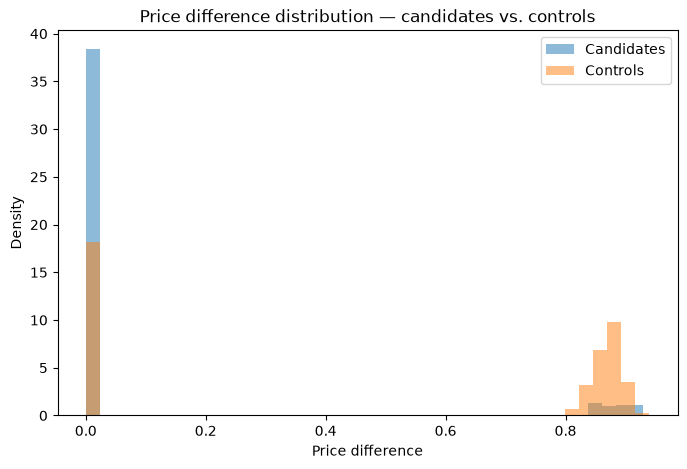

In [47]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(cand_price_diffs, bins=40, alpha=0.5, density=True, label="Candidates")
ax.hist(ctrl_price_diffs, bins=40, alpha=0.5, density=True, label="Controls")
ax.set_xlabel("Price difference")
ax.set_ylabel("Density")
ax.set_title("Price difference distribution — candidates vs. controls")
ax.legend()
plt.show()

## 9. Visual summary across all sync/direction/outcome metrics

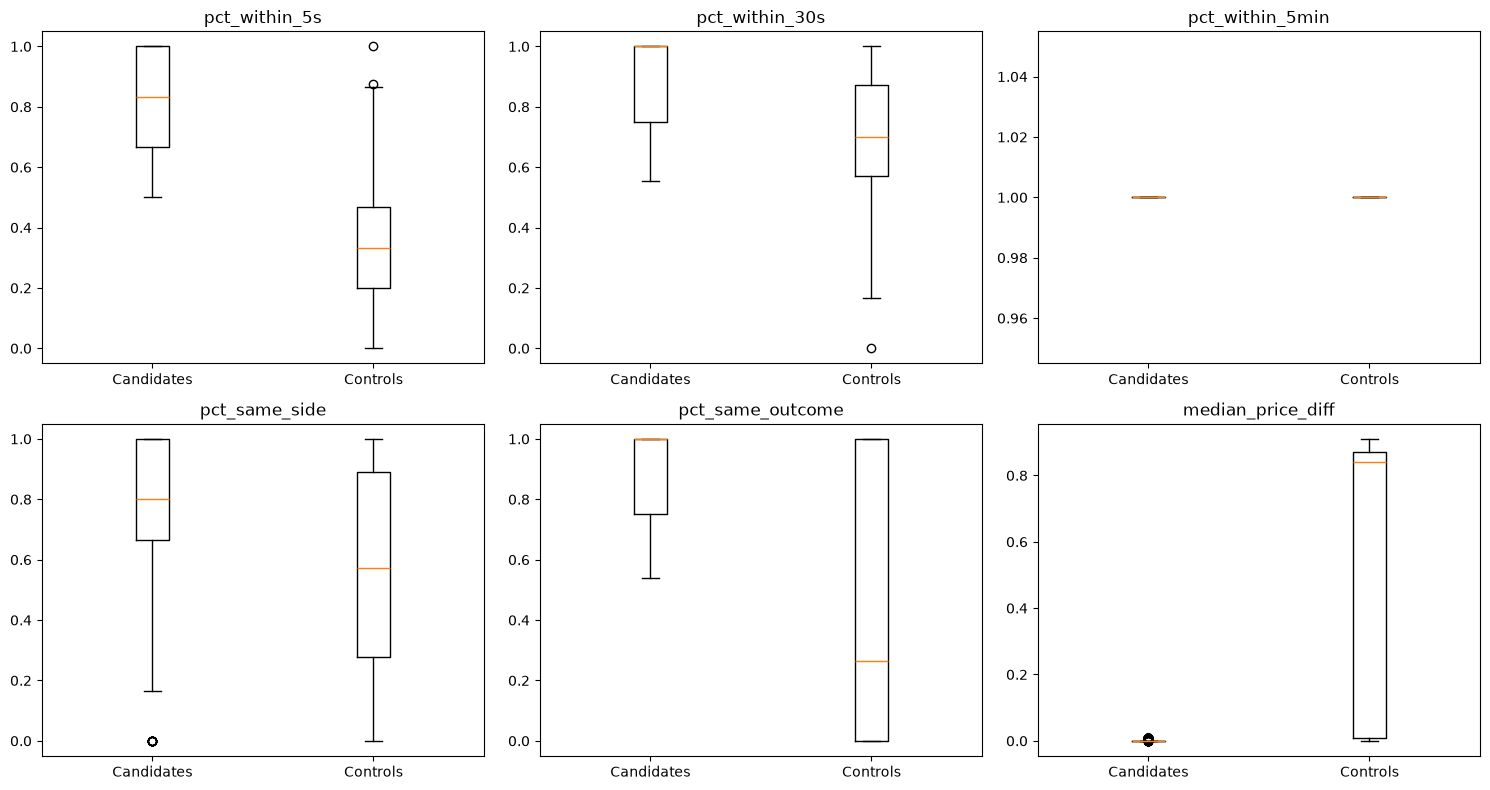

In [48]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
plot_metrics = ["pct_within_5s", "pct_within_30s", "pct_within_5min",
                "pct_same_side", "pct_same_outcome", "median_price_diff"]

for ax, metric in zip(axes.flat, plot_metrics):
    ax.boxplot(
        [candidate_df[metric].dropna(), control_df[metric].dropna()],
        tick_labels=["Candidates", "Controls"]
    )
    ax.set_title(metric)

plt.tight_layout()
plt.show()

## 10. Verdict

In [49]:
print("=" * 70)
print("SUMMARY — Candidates vs. matched controls")
print("=" * 70)
print(f"Candidate pairs: {len(candidate_df)}   Matched control pairs: {len(control_df)}")
print(f"n_events matching check p-value: {p:.4f} (want NOT significant — confirms fair comparison)\n")

print("Dimension-by-dimension results:")
print(comparison_table.to_string(index=False))
print()
print("Repetition thresholds:")
print(pd.DataFrame(rep_rows).to_string(index=False))
print()
print("Persistence:")
print(pd.DataFrame(persistence_rows).to_string(index=False))
print()
print("Price distribution (KS test):", f"stat={ks_stat:.4f}, p={ks_p:.2e}")
print()
n_sig = comparison_table["significant"].sum()
print(f"{n_sig} / {len(comparison_table)} dimensions show a statistically significant "
      f"(p<0.001) difference from matched controls.")
print()
print("Read the ratio column above alongside significance — a p-value can be tiny with a")
print("trivial effect size at this sample size. A convincing 'genuinely unusual' claim needs")
print("BOTH significance AND a ratio meaningfully different from 1.0 (e.g., >1.5x or <0.67x).")

SUMMARY — Candidates vs. matched controls
Candidate pairs: 479   Matched control pairs: 57
n_events matching check p-value: 0.0000 (want NOT significant — confirms fair comparison)

Dimension-by-dimension results:
           metric  candidate_median  control_median    ratio      p_value  significant
    pct_within_1s          0.750000        0.181818 4.125000 1.802033e-23         True
    pct_within_5s          0.833333        0.333333 2.500000 1.082026e-31         True
   pct_within_10s          0.888889        0.454545 1.955556 6.592176e-31         True
   pct_within_30s          1.000000        0.700000 1.428571 4.738444e-12         True
  pct_within_1min          1.000000        0.857143 1.166667 2.050357e-06         True
  pct_within_5min          1.000000        1.000000 1.000000 1.000000e+00        False
    pct_same_side          0.800000        0.571429 1.400000 8.902442e-07         True
 pct_same_outcome          1.000000        0.263158 3.800000 8.995362e-16         True
med

In [50]:
# Compute metrics for the FULL non-candidate pool (not a subsample)
all_noncandidate_metrics = []
for pair_key in non_candidate_pool["pair_key"]:
    m = pair_metrics(pair_key, temporal_edges)
    if m is not None:
        all_noncandidate_metrics.append(m)

full_control_df = pd.DataFrame(all_noncandidate_metrics)
full_control_df["group"] = "control"
print("Full non-candidate pool with metrics:", full_control_df.shape)

Full non-candidate pool with metrics: (3484, 24)


In [51]:
from numpy.polynomial import polynomial as P

full_combined = pd.concat([candidate_df, full_control_df], ignore_index=True)
full_combined["log_n_events"] = np.log1p(full_combined["n_events"])
full_combined["is_candidate"] = full_combined["group"] == "candidate"

residual_rows = []
for metric in comparison_metrics:
    valid = full_combined[[metric, "log_n_events", "is_candidate"]].dropna()

    # Fit metric ~ log_n_events on the FULL population (candidates + controls together)
    coeffs = np.polyfit(valid["log_n_events"], valid[metric], deg=1)
    predicted = np.polyval(coeffs, valid["log_n_events"])
    residual = valid[metric] - predicted

    cand_resid = residual[valid["is_candidate"]]
    ctrl_resid = residual[~valid["is_candidate"]]

    stat, p = mannwhitneyu(cand_resid, ctrl_resid, alternative="two-sided")
    residual_rows.append({
        "metric": metric,
        "candidate_residual_median": cand_resid.median(),
        "control_residual_median": ctrl_resid.median(),
        "p_value": p,
        "significant": p < 0.001,
    })

residual_table = pd.DataFrame(residual_rows)
residual_table

,metric,candidate_residual_median,control_residual_median,p_value,significant
0,pct_within_1s,3.438080e-01,-1.011515e-01,1.313551e-113,True
1,pct_within_5s,3.678416e-01,-1.560498e-01,1.190484e-138,True
2,pct_within_10s,3.750032e-01,-7.540748e-02,5.098113e-114,True
3,pct_within_30s,2.696684e-01,-3.807203e-03,1.642394e-34,True
4,pct_within_1min,1.831124e-01,4.108377e-02,1.377599e-09,True
5,pct_within_5min,1.110223e-16,1.110223e-16,9.341774e-02,False
6,pct_same_side,2.710040e-01,-1.926266e-02,2.342072e-50,True
7,pct_same_outcome,4.887789e-01,-1.735669e-01,1.065626e-74,True
8,median_price_diff,-4.215507e-01,4.080348e-01,1.524941e-135,True
9,price_diff_std,-1.252113e-01,-1.234245e-01,6.410568e-01,False


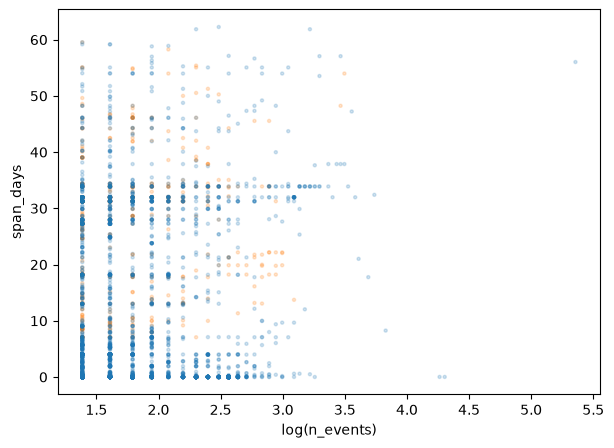

In [52]:
# Does the linear fit visibly capture the relationship, or is there curvature the residual missed?
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(full_combined["log_n_events"], full_combined["span_days"], s=5, alpha=0.2, c=full_combined["is_candidate"].map({True: "C1", False: "C0"}))
ax.set_xlabel("log(n_events)")
ax.set_ylabel("span_days")
plt.show()